---
title: "02 · Investigate the signal"
---

The goal is to understand class overlap and related measurements using development data. These figures explain the modeling choices; none is a clinical decision rule.

In [1]:
from cancer_study.common import root, read_json
from IPython.display import SVG, display
import pandas as pd

project = root()
metrics_dir = project / "reports/metrics"
def figure(name):
    display(SVG(filename=str(project / "site/assets" / name)))

from cancer_study.datasets import load_development
development = load_development(project)
assert development.partition.eq("development").all()
print(f"Exploring {len(development)} development samples.")

Exploring 455 development samples.


## First look: separation and overlap

Each point is one sample. Mean radius and worst concave points show a visible relationship with the recorded class, while overlapping observations make a one-feature rule inadequate.

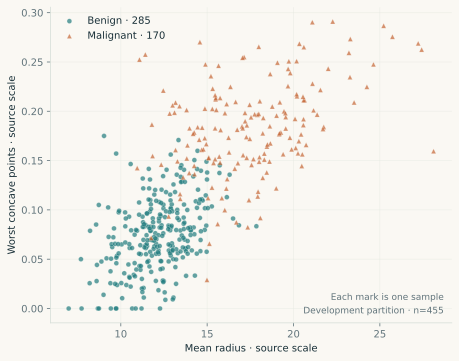

In [2]:
#| fig-alt: "Development samples by mean radius and worst concave points, showing class separation and overlap."
figure("sample-map.svg")

## Compare distributions

Density curves summarize the observed development distributions. Their smoothing is descriptive; the model uses the original numeric features. Vertical lines indicate class medians.

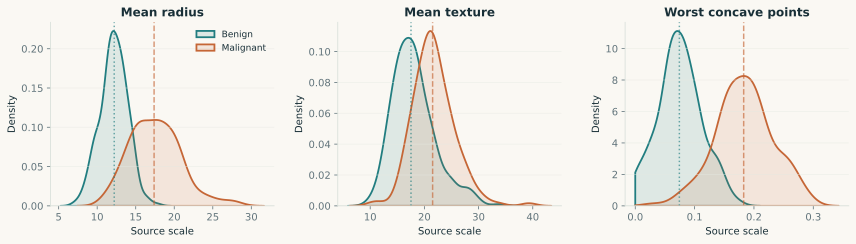

,diagnosis,samples,median_radius_mean,median_texture_mean,median_concave_points_worst,radius_q25,radius_q75
0,B,285,12.210,17.53,0.07431,11.1400,13.3700
1,M,170,17.385,21.52,0.18270,15.1525,19.6875


In [3]:
#| fig-alt: "Development class distributions of mean radius, mean texture, and worst concave points, with medians and overlapping ranges."
figure("distributions.svg")
with __import__("duckdb").connect() as connection:
    connection.register("samples", development)
    display(connection.execute((project / "sql/feature_summary.sql").read_text()).df())

## Check related measurements

Radius, perimeter, and area describe related aspects of size. Correlation motivates comparing a regularized model with nonlinear alternatives; it does not establish causation or justify a full-data supervised feature ranking.

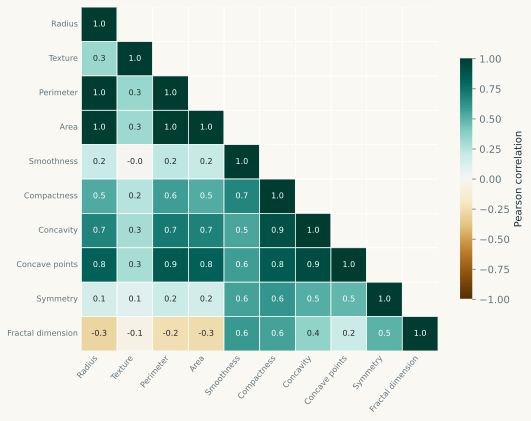

medians                         {'radius_mean': {'B': 12.21, 'M': 17.385}, 'te...
radius_perimeter_correlation                                             0.997815
radius_area_correlation                                                   0.98674
development_rows                                                              455
dtype: object

In [4]:
#| fig-alt: "Pearson correlations among ten mean measurements, with strong relationships between size-related features."
figure("correlations.svg")
display(pd.Series(read_json(metrics_dir / "exploration.json")))

## Decision

Retain all thirty features and use regularization. Fit scaling inside validation folds for scale-sensitive models. Compare a small, fixed set of candidates under the same protocol. Measurement units are not asserted where the source dictionary does not establish them.